# 🔭 Day 5 — Observability & Reliability
## *"Zia Went Quietly Wrong"* · LangSmith tracing, logs, metrics, PII redaction and alerts that mean something

**FDE Program · Phase 3** · ⏱️ ~3 hours · 🧰 LangSmith · LangChain `PIIMiddleware` · usage callbacks

---

### 🎬 Previously on Zia...
Clean tickets (Day 1) · gated releases (Day 2) · canary + rollback (Day 3) · fast and affordable on playoff night (Day 4).

### 🎬 This episode
Tuesday 10:00 am. Someone on the billing team adds one "helpful" line to Zia's system prompt:
> *"If a message contains a number, it's probably about money — classify it as BILL_HIGH."*

It's "just a prompt tweak", so it skips the pipeline. 🤷

For **three days**, every dashboard is **green**: fast, zero errors. Meanwhile *"No signal at the stadium since **7pm**"* gets the reply *"Please check your latest bill."* 🤦

Friday, the network team asks why outage tickets dropped during a week with two tower failures. Nobody can explain which messages were affected, or why.

### 🕷️ Spider-Sense
Peter Parker's spider-sense doesn't tingle for every noise in New York — only for **real danger**, and early enough to act. Good monitoring is a spider-sense: **quiet when things are fine, loud when they're not, and pointing at the danger.**

### 🗺️ Today's map
| # | Section | Type |
|---|---|---|
| 1 | Logs, metrics, traces · LangSmith · what to record (and what not to) | 🧠 Concept 1 |
| 2 | Demo: trace one message end to end and find the bug | 🔬 Demo 1 |
| 3 | Signals that matter for AI · alerts · runbooks · PII redaction | 🧠 Concept 2 |
| 4 | Demo: three days of dashboards — green machines, broken behaviour | 🔬 Demo 2 |
| 5 | Hands-on: the alert that would have caught it on Tuesday | 🏋️ Exercise |
| 6 | Solution · anti-patterns · best practices | ✅ |

## 📦 Installation
```bash
pip install langchain langchain-openai langsmith langchain-mcp-adapters mcp python-dotenv pandas matplotlib
```
Create a file called `.env` next to this notebook:
```
OPENAI_API_KEY=sk-...
LANGSMITH_API_KEY=lsv2_...     # optional, free tier at smith.langchain.com
```

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

project_dir = Path.cwd()
candidates = [
    project_dir / ".env",
    project_dir / "Dataset" / ".env",
    project_dir.parent / ".env",
]

loaded = False
for candidate in candidates:
    if candidate.exists():
        load_dotenv(candidate, override=True)
        loaded = True
        break

if not loaded:
    load_dotenv()

for key in ["OPENAI_API_KEY", "LANGSMITH_API_KEY"]:
    value = os.getenv(key)
    if value:
        os.environ[key] = value.strip().strip('"').strip("'")

os.environ["LANGSMITH_PROJECT"] = "zia-day-6"
if os.getenv("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_TRACING"] = "true"    # every LangChain call now shows up in LangSmith
    print("✅ LangSmith tracing is ON  → https://smith.langchain.com")
else:
    print("ℹ️  LangSmith is off (add LANGSMITH_API_KEY to .env to see traces)")

if os.getenv("OPENAI_API_KEY"):
    zia_agent = create_agent(
        model="gpt-4o-mini",
        tools=[],
        system_prompt="You are Zia from Zing Wireless. Reply in one short sentence.",
    )
    print("✅ Agent ready:", type(zia_agent).__name__)
else:
    zia_agent = None
    print("⚠️ Add OPENAI_API_KEY to .env to initialize the Zia agent.")

if zia_agent:
    result = zia_agent.invoke({"messages": [{"role": "user", "content": "My bill is $240 and my internet is super slow."}]})
    print(result["messages"][-1].content)


✅ LangSmith tracing is ON  → https://smith.langchain.com
✅ Agent ready: CompiledStateGraph
I recommend checking your internet speed and contacting customer support for assistance with your bill and service issues.


In [2]:
# 🌍 Zing Wireless — the world of our story (same in every notebook)
CATEGORIES = ["NO_SIGNAL", "BILL_HIGH", "DATA_PLAN", "SLOW_INTERNET", "SIM_ISSUE"]

TEAM_FOR = {"NO_SIGNAL": "NETWORK-OPS", "SLOW_INTERNET": "NETWORK-OPS",
            "BILL_HIGH": "BILLING-OPS", "DATA_PLAN": "PLANS-OPS", "SIM_ISSUE": "SIM-OPS"}

TOWER_FOR = {"Stadium": "TWR-017", "Midtown": "TWR-017", "Brooklyn": "TWR-031",
             "Queens": "TWR-044", "Jersey City": "TWR-052"}

# Real customers: short, emotional, sometimes in Spanish 🇺🇸🇲🇽
SAMPLE_MESSAGES = [
    {"id": "M01", "customer": "C101", "place": "Stadium",     "lang": "en", "label": "NO_SIGNAL",     "text": "No signal at the stadium since 7pm!!"},
    {"id": "M02", "customer": "C102", "place": "Midtown",     "lang": "en", "label": "NO_SIGNAL",     "text": "Zero bars in Midtown for 2 hours, can't call anyone"},
    {"id": "M03", "customer": "C103", "place": "Queens",      "lang": "es", "label": "NO_SIGNAL",     "text": "No tengo señal en Queens desde las 9"},
    {"id": "M04", "customer": "C104", "place": "Brooklyn",    "lang": "en", "label": "BILL_HIGH",     "text": "Why is my bill $240? It's usually $65"},
    {"id": "M05", "customer": "C105", "place": "Queens",      "lang": "es", "label": "BILL_HIGH",     "text": "Mi factura es muy alta este mes, $180"},
    {"id": "M06", "customer": "C106", "place": "Jersey City", "lang": "en", "label": "DATA_PLAN",     "text": "Bought the 10GB add-on but it isn't showing"},
    {"id": "M07", "customer": "C107", "place": "Brooklyn",    "lang": "es", "label": "DATA_PLAN",     "text": "Pagué el plan de datos y no funciona"},
    {"id": "M08", "customer": "C108", "place": "Midtown",     "lang": "en", "label": "SLOW_INTERNET", "text": "Internet is super slow, videos keep buffering"},
    {"id": "M09", "customer": "C109", "place": "Queens",      "lang": "es", "label": "SLOW_INTERNET", "text": "El internet está muy lento en Queens"},
    {"id": "M10", "customer": "C110", "place": "Jersey City", "lang": "en", "label": "SIM_ISSUE",     "text": "My new eSIM won't activate"},
    {"id": "M11", "customer": "C111", "place": "Brooklyn",    "lang": "en", "label": "SIM_ISSUE",     "text": "Phone says No SIM card after the update"},
    {"id": "M12", "customer": "C112", "place": "Stadium",     "lang": "en", "label": "NO_SIGNAL",     "text": "Calls keep dropping at the game since 8pm, fix it!"},
]
print(f"🌍 Zing Wireless loaded: {len(SAMPLE_MESSAGES)} sample messages, {len(CATEGORIES)} complaint types")

🌍 Zing Wireless loaded: 12 sample messages, 5 complaint types


---
## 🧠 Section 1 (Concept 1): Logs, Metrics and Traces

### ⚾ Baseball explains it
| Pillar | Baseball | At Zing |
|---|---|---|
| **Logs** | The **play-by-play** — every pitch, in detail | "What happened to message M01?" |
| **Metrics** | The **box score** — numbers over time | "How many tickets per hour? How fast?" |
| **Traces** | **Statcast** — the full path of one pitch, from release to the bat | "Which step made Zia send M01 to billing?" |

The box score tells you you're losing. The play-by-play and Statcast tell you **why**.

### LangSmith = Zia's flight recorder
With two environment variables (`LANGSMITH_TRACING=true` + an API key), **every LangChain call is recorded**: the prompt, the answer, tokens, cost, time, tool calls — nested in one tree per request. You can also:
- add **tags** and **metadata** (e.g. `prompt_version=v7`) to search later,
- trace your own plain Python functions with `@traceable`,
- build dashboards and alerts on top.

### What to record — and what not to
| Record ✅ | Never record ❌ |
|---|---|
| trace id, step, time taken, **prompt version**, model | customers' card numbers, emails, passwords unmasked |
| the category Zia chose + why | API keys or tokens |
| which **rule or model** made the decision | anything you wouldn't want read aloud in court |

### ✅ What went well vs ❌ what didn't
| | Story | Lesson |
|---|---|---|
| ❌ | **Equifax (2017)** — an expired security certificate on a monitoring device meant encrypted traffic wasn't being inspected; attackers took data for weeks before anyone noticed. Data on ~147 million Americans was exposed. | Monitoring that silently stops is worse than none — it gives false comfort. |
| ❌ | **AT&T nationwide outage (Feb 2024)** — a network configuration change during an expansion knocked out service for many customers for hours, including 911 calls in some areas. | Watch what changed — config changes are changes. |
| ❌ | **Meta outage (Oct 2021)** — a configuration change took Facebook, Instagram and WhatsApp offline for ~6 hours; the internal tools needed to fix it depended on the same network. | Your monitoring must not depend on the thing it watches. |
| ✅ | **Google SRE** — "four golden signals" and error budgets turned "is it OK?" into numbers that drive decisions. | Measure what users feel. |

---
## 🔬 Demo 1: Trace one message end to end

### Step 1 — Monday's prompt and Tuesday's prompt

In [5]:
from typing import Literal
from pydantic import BaseModel

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

class Label(BaseModel):
    category: Literal["NO_SIGNAL", "BILL_HIGH", "DATA_PLAN", "SLOW_INTERNET", "SIM_ISSUE"]

classifier = llm.with_structured_output(Label)

PROMPTS = {
    "v6": f"You classify Zing Wireless customer messages. Categories: {CATEGORIES}. English or Spanish.",
    "v7": f"You classify Zing Wireless customer messages. Categories: {CATEGORIES}. English or Spanish. "
          "If a message contains a number, it is about money: classify it as BILL_HIGH.",
}

live_prompt = "v7"

### Step 2 — Structured logs + a trace id
One JSON line per decision, each with a **trace id** that follows the message through every step. `@traceable` sends this function to LangSmith too (when tracing is on).

In [6]:
import json, uuid, time
from langsmith import traceable

LOGS = []

def log(**fields):
    LOGS.append(fields)
    print(json.dumps(fields))

@traceable(name="zia.handle_message")
def handle_message(message):
    trace_id = uuid.uuid4().hex[:8]
    start = time.perf_counter()
    label = classifier.invoke([("system", PROMPTS[live_prompt]), ("user", message["text"])],
                              config={"tags": ["zia", live_prompt], "metadata": {"prompt_version": live_prompt,
                                                                                "message_id": message["id"]}})
    log(trace_id=trace_id, message_id=message["id"], step="classify", prompt_version=live_prompt,
        category=label.category, ms=round((time.perf_counter() - start) * 1000))
    return label.category

handle_message(SAMPLE_MESSAGES[0])      # "No signal at the stadium since 7pm!!"

{"trace_id": "372eb061", "message_id": "M01", "step": "classify", "prompt_version": "v7", "category": "NO_SIGNAL", "ms": 1124}


'NO_SIGNAL'

> 🕵️ **Case closed in one line:** the log says `prompt_version: v7` and `category: BILL_HIGH` for a message about **no signal**. In LangSmith, filter by `metadata.prompt_version = v7` and you'll see every affected message, with the exact prompt the model received.
>
> Without the prompt version in the log, you'd blame the model and spend a week "retraining" something that never changed.

### Step 3 — Count tokens and cost with a built-in callback

In [5]:
from langchain_core.callbacks import UsageMetadataCallbackHandler

usage = UsageMetadataCallbackHandler()
for m in SAMPLE_MESSAGES[:5]:
    classifier.invoke([("system", PROMPTS["v6"]), ("user", m["text"])], config={"callbacks": [usage]})
print("Tokens used, per model:", usage.usage_metadata)

Tokens used, per model: {'gpt-4o-mini-2024-07-18': {'input_token_details': {'audio': 0, 'cache_read': 0}, 'input_tokens': 587, 'output_tokens': 32, 'output_token_details': {'audio': 0, 'reasoning': 0}, 'total_tokens': 619}}


---
## 🧠 Section 3 (Concept 2): Signals, Alerts, Runbooks and Privacy

### Two kinds of health
| Is the **machine** healthy? (golden signals) | Is the **behaviour** healthy? (AI signals) |
|---|---|
| Latency | **Category mix** — did "NO_SIGNAL" suddenly drop? |
| Traffic | **Re-contact rate** — customers coming back annoyed |
| Errors | **Fallback rate** — how often rules replaced the AI |
| Saturation | **Cost per message** — prompt bloat, retry storms |

🩺 A patient can have a normal pulse and temperature and still be confused. A good doctor checks both. **This week, every machine signal was green.**

### Alerts that mean something
| ✅ Good alert | ❌ Bad alert |
|---|---|
| Tied to **customer impact** | "CPU > 70%" at 3 am with no impact |
| Compares with the **right baseline** (same hour yesterday) | A fixed number that's wrong on playoff night |
| Comes with a **runbook** (what to check, how to fix) | "Something's wrong, good luck" |
| Rare enough to be trusted | Fires every day → ignored (the boy who cried wolf 🐺) |

### Privacy: redact before you log
LangChain's built-in **`PIIMiddleware`** finds emails, card numbers, IP addresses and more, and **redacts, masks or blocks** them before they reach the model — and therefore before they reach your traces and logs.

🕷️ *Spider-Man: No Way Home* — Mysterio reveals Peter's identity to the whole world in one broadcast, and nothing can undo it. **Once personal data is out, you can't put it back.**

---
## 🔬 Demo 2: Three days of dashboards

### Step 1 — Redact personal data before anything is recorded

In [7]:
from langchain.agents import create_agent
from langchain.agents.middleware import PIIMiddleware

safe_zia = create_agent(
    llm, tools=[],
    system_prompt="You are Zia from Zing Wireless. Reply in one short sentence.",
    middleware=[PIIMiddleware("email", strategy="redact"), PIIMiddleware("credit_card", strategy="mask")],
)
result = safe_zia.invoke({"messages": [{"role": "user", "content":
          "No signal again! I'm jane.doe@gmail.com and my card is 4111-1111-1111-1111, refund me"}]})
print("What the model (and the trace) saw:", result["messages"][0].content)

What the model (and the trace) saw: No signal again! I'm [REDACTED_EMAIL] and my card is ****-****-****-1111, refund me


### Step 2 — Simulate Monday (prompt v6), Tuesday and Wednesday (prompt v7)
To keep it fast and cheap, we ask each prompt version about each sample message once, then replay those answers for 300 messages a day.

In [8]:
import random
random.seed(5)
ANSWERS = {v: {m["text"]: classifier.invoke([("system", p), ("user", m["text"])]).category for m in SAMPLE_MESSAGES}
           for v, p in PROMPTS.items()}

days = {"Mon": "v6", "Tue": "v7", "Wed": "v7"}
dashboard = []
for day, version in days.items():
    msgs = [random.choice(SAMPLE_MESSAGES) for _ in range(300)]
    chosen = [ANSWERS[version][m["text"]] for m in msgs]
    dashboard.append({
        "day": day, "prompt": version,
        "p95_latency_s": round(random.uniform(1.8, 2.1), 2),                  # machine signals: all normal
        "error_rate": 0.0,
        "no_signal_share": round(chosen.count("NO_SIGNAL") / len(chosen), 2),  # behaviour signal
        "bill_share": round(chosen.count("BILL_HIGH") / len(chosen), 2),
    })

import pandas as pd
pd.DataFrame(dashboard)

,day,prompt,p95_latency_s,error_rate,no_signal_share,bill_share
0,Mon,v6,1.82,0.0,0.35,0.16
1,Tue,v7,1.81,0.0,0.33,0.16
2,Wed,v7,1.93,0.0,0.39,0.16


Matplotlib is building the font cache; this may take a moment.


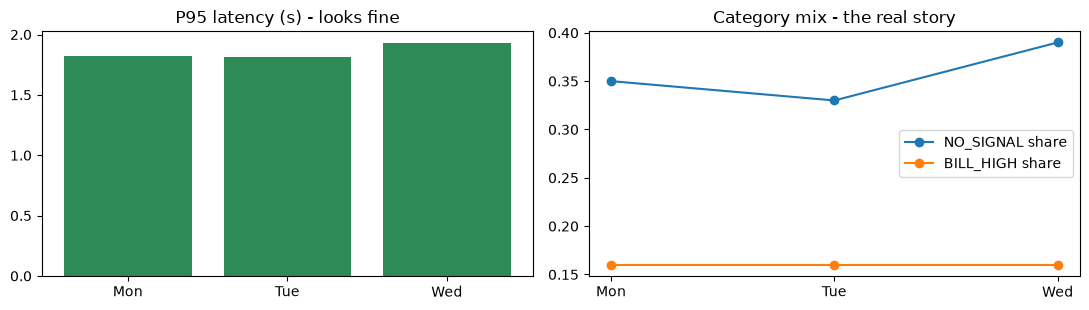

In [9]:
import matplotlib.pyplot as plt
df = pd.DataFrame(dashboard)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].bar(df.day, df.p95_latency_s, color="seagreen"); ax[0].set_title("P95 latency (s) - looks fine")
ax[1].plot(df.day, df.no_signal_share, "o-", label="NO_SIGNAL share")
ax[1].plot(df.day, df.bill_share, "o-", label="BILL_HIGH share"); ax[1].set_title("Category mix - the real story"); ax[1].legend()
plt.tight_layout(); plt.show()

> 💡 **Two dashboards, two truths.** The machine panel says "all good". The behaviour panel says "since Tuesday we've been telling people with no signal to check their bill." Only the second one has a spider-sense.

---
## 🏋️ Hands-on Exercise: Catch it on Tuesday (30 min)

**Q1.** Write `no_signal_alert(dashboard, day_index)` that returns an alert dict if the `no_signal_share` on that day is **more than 30% lower** than the day before; otherwise `None`. The alert must include `day`, `observed`, `baseline` and a `runbook` list with **at least 3 steps**.

**Q2.** Write `decisions_by_prompt(logs)` that counts, from the `LOGS` list, how many decisions each `prompt_version` made per category. *(First run `handle_message` on all `SAMPLE_MESSAGES` with `live_prompt = "v7"` so you have logs.)*

**Q3.** Fix it: set `live_prompt` back to `"v6"`, re-run `handle_message` on message M01, and show the category is now `NO_SIGNAL`.

In [10]:
# 🏋️ YOUR CODE HERE
def no_signal_alert(dashboard, day_index):
    # TODO Q1
    return None

def decisions_by_prompt(logs):
    # TODO Q2
    return {}

# TODO Q3

In [11]:
# 🎯 Self-check
def check_day5():
    tue = no_signal_alert(dashboard, 1)
    ok1 = bool(tue) and len(tue.get("runbook", [])) >= 3 and tue["observed"] < tue["baseline"]
    ok2 = no_signal_alert(dashboard, 2) is None                  # Wed vs Tue: no new drop
    counts = decisions_by_prompt(LOGS)
    ok3 = "v7" in counts
    for name, ok in [("Q1 fires on Tuesday with a runbook", ok1), ("Q1 quiet when nothing changed", ok2),
                     ("Q2 counts decisions per prompt version", ok3), ("Q3 live prompt is back to v6", live_prompt == "v6")]:
        print(("✅ " if ok else "❌ ") + name)
check_day5()

❌ Q1 fires on Tuesday with a runbook
✅ Q1 quiet when nothing changed
❌ Q2 counts decisions per prompt version
❌ Q3 live prompt is back to v6


---
## ✅ Solution

In [12]:
def no_signal_alert(dashboard, day_index):
    if day_index == 0: return None
    today, yesterday = dashboard[day_index], dashboard[day_index - 1]
    if today["no_signal_share"] < yesterday["no_signal_share"] * 0.7:
        return {"day": today["day"], "observed": today["no_signal_share"], "baseline": yesterday["no_signal_share"],
                "impact": "customers with no signal are getting the wrong reply",
                "runbook": ["1. Check what changed in the last 24h — code, model AND prompts",
                            "2. In LangSmith, filter NO_SIGNAL-looking messages by prompt_version",
                            "3. If a prompt change caused it, switch back to the last good version",
                            "4. Post in #zia-incidents and schedule a blameless review"]}
    return None

def decisions_by_prompt(logs):
    out = {}
    for line in logs:
        out.setdefault(line["prompt_version"], {}).setdefault(line["category"], 0)
        out[line["prompt_version"]][line["category"]] += 1
    return out

for i in range(3):
    print(dashboard[i]["day"], "→", no_signal_alert(dashboard, i))

live_prompt = "v7"
for m in SAMPLE_MESSAGES: handle_message(m)
print("\nDecisions by prompt:", decisions_by_prompt(LOGS))

live_prompt = "v6"
print("\nAfter the fix, M01 →", handle_message(SAMPLE_MESSAGES[0]))
check_day5()

Mon → None
Tue → None
Wed → None
{"trace_id": "5a0e8f1b", "message_id": "M01", "step": "classify", "prompt_version": "v7", "category": "NO_SIGNAL", "ms": 1282}
{"trace_id": "d85bbb17", "message_id": "M02", "step": "classify", "prompt_version": "v7", "category": "NO_SIGNAL", "ms": 1121}
{"trace_id": "b69f97ee", "message_id": "M03", "step": "classify", "prompt_version": "v7", "category": "NO_SIGNAL", "ms": 883}
{"trace_id": "3eebef6a", "message_id": "M04", "step": "classify", "prompt_version": "v7", "category": "BILL_HIGH", "ms": 998}
{"trace_id": "e4efc475", "message_id": "M05", "step": "classify", "prompt_version": "v7", "category": "BILL_HIGH", "ms": 1374}
{"trace_id": "51042e2c", "message_id": "M06", "step": "classify", "prompt_version": "v7", "category": "DATA_PLAN", "ms": 881}
{"trace_id": "42aeed83", "message_id": "M07", "step": "classify", "prompt_version": "v7", "category": "DATA_PLAN", "ms": 797}
{"trace_id": "186623eb", "message_id": "M08", "step": "classify", "prompt_version"

**Debrief:** the real fix is three things: **(1)** prompt changes go through the pipeline and canary like everything else (Days 2–3), **(2)** a **behaviour alert** on the category mix, **(3)** the **prompt version in every log and trace**, so the cause is one search away.

---
## 🚫 Anti-patterns — observability
| Anti-pattern | At Zing | Everyday version |
|---|---|---|
| **Only machine metrics** | Green dashboards, wrong answers | A car dashboard that shows fuel but not that you're on the wrong freeway |
| **`print()` logs, no trace id** | Can't follow one message | A play-by-play with no inning numbers |
| **Prompt changes skip the pipeline** | "Just a tweak" broke three days | "It's a small change" — famous last words |
| **Alerts without runbooks** | Woken up with no idea what to do | A fire alarm with no exit signs |
| **Noisy alerts** | 40 a day, all ignored | Peter's spider-sense tingling at every pigeon |
| **Logging personal data** | Card numbers in traces | Reading customers' passwords over the stadium PA |

## ✅ Best practices
- [ ] **LangSmith tracing** on from day one; add **tags + metadata** (prompt version, customer segment).
- [ ] One structured log line per decision, with a **trace id** and the **prompt version**.
- [ ] Watch **behaviour** (category mix, re-contact, fallback rate, cost), not just machines.
- [ ] Every alert: customer impact + the right baseline + a **runbook**.
- [ ] **`PIIMiddleware`** (or similar) so personal data never reaches the model, logs or traces.
- [ ] Monitoring and alerting that don't depend on the system they watch.

---
## 📝 Summary
| Concept | One-liner | Tool |
|---|---|---|
| Logs / metrics / traces | Play-by-play, box score, Statcast | `LOGS`, dashboard, LangSmith |
| Tracing | Every step of one request, in one tree | `LANGSMITH_TRACING`, `@traceable`, tags/metadata |
| Cost tracking | Tokens per model | `UsageMetadataCallbackHandler` |
| Behaviour signals | Healthy machine ≠ healthy answers | Category-mix chart |
| Alerts + runbooks | Wake a person only with impact and a plan | `no_signal_alert()` |
| Privacy | Redact before recording | `PIIMiddleware` |

### 🔜 Next episode — Evaluation Frameworks: *"Is the New Zia Actually Better?"*
Marketing loves a shiny new prompt for Black Friday. It "feels" better in the demo. Next: golden test sets, LLM-as-judge, LangSmith experiments — and why "it feels better" can cost $100 billion in a day.